# Lesson 03 — Loss: one number for "how wrong"

Goal: build **MSE** (Mean Squared Error) yourself, use it to score lines, and *see* the loss.

- `y` = real answers
- `y_hat` = the model's predictions (ŷ)
- MSE = average of (y − ŷ)²

Run each cell with **Shift+Enter**. Fill in every `TODO`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def predict(x, m, b):
    return m * x + b

## Step 1 — Write MSE yourself

**TODO:** Write `mse(y, y_hat)` in three lines, one per word of the name, read backwards:
1. **error**: the misses
2. **squared**: square each miss
3. **mean**: average them

*Hints:* NumPy works on whole arrays: `a - b`, `a ** 2`, `np.mean(a)`. Don't use a loop.

In [12]:
def mse(y, y_hat):
    # TODO
    err = y - y_hat # error
    err_squared = err ** 2 # squared
    mean = np.mean(err_squared) # mean
    return mean # mse

## Step 2 — Check it against the hand-worked example

Three pizzas, two lines. By hand, we got: **Line A → 1**, **Line B → 10.67**.

**TODO:** Compute both with your `mse`. Do they match?

In [3]:
x = np.array([6, 10, 14])
y = np.array([7, 11, 15])

# Line A: m=1, b=0      Line B: m=0, b=11
# TODO 
y_hat_a = predict(x, 1, 0)
y_hat_b = predict(x, 0, 11)

mse_a = mse(y, y_hat_a)
mse_b = mse(y, y_hat_b)

print("MSE for Line A: ", mse_a)
print("MSE for Line B: ", mse_b)

MSE for Line A:  1.0
MSE for Line B:  10.666666666666666


## Step 3 — Score your Lesson 01 line

Back to the 5 pizzas from Lesson 01. You fit `m = 1.029`, `b = 1.089` by eye.

**TODO:** Compute the MSE of your line. Then try 2–3 other `(m, b)` pairs. Can you beat your own score?

In [18]:
sizes  = np.array([6, 8, 10, 12, 14])
prices = np.array([7.0, 9.5, 11.0, 13.8, 15.6])

# TODO
prices_hat = predict(sizes, 1.029, 1.089)
mse_loss = mse(prices, prices_hat)
print("MSE with m = 1.029 and b = 1.089 is: ", mse_loss)

prices_hat = predict(sizes, 1.030, 1.090)
mse_loss = mse(prices, prices_hat)
print("MSE with m = 1.030 and b = 1.090 is: ", mse_loss)

prices_hat = predict(sizes, 1.031, 1.090)
mse_loss = mse(prices, prices_hat)
print("MSE with m = 1.031 and b = 1.090 is: ", mse_loss)

prices_hat = predict(sizes, 1.0322, 1.090)
mse_loss = mse(prices, prices_hat)
print("MSE with m = 1.0322 and b = 1.090 is: ", mse_loss)
# My attempts (m, b) -> MSE:
#   (1.029, 1.089) -> 0.07752900000000015
#   (1.030, 1.090) -> 0.07690000000000025
#   (1.031, 1.090) -> 0.07648799999999994
#   (1.0322, 1.090) -> 0.07627871999999991

MSE with m = 1.029 and b = 1.089 is:  0.07752900000000015
MSE with m = 1.030 and b = 1.090 is:  0.07690000000000025
MSE with m = 1.031 and b = 1.090 is:  0.07648799999999994
MSE with m = 1.0322 and b = 1.090 is:  0.07627871999999991


## Step 4 — See the loss as a curve ⭐ (the important one)

Keep `b = 1.089` **fixed**. Try **many** values of `m`, compute the MSE for each, and plot **MSE (up) against m (across)**.

**TODO:**
1. `ms = np.linspace(0.5, 1.5, 101)` gives 101 values of m.
2. For each `m` in `ms`, compute the MSE on the pizzas. Collect them in a list.
3. Plot `ms` vs your list of losses.
4. Find the `m` with the **lowest** loss.

*Hints:* `np.argmin(losses)` gives the **position** of the smallest value. `ms[that_position]` gives the m.

**Questions (answer as comments):**
- What **shape** is the curve?
- Is your eyeballed m = 1.029 near the bottom? Left or right of it?
- If you were standing on this curve at m = 0.7, which way would you walk to reduce the loss?

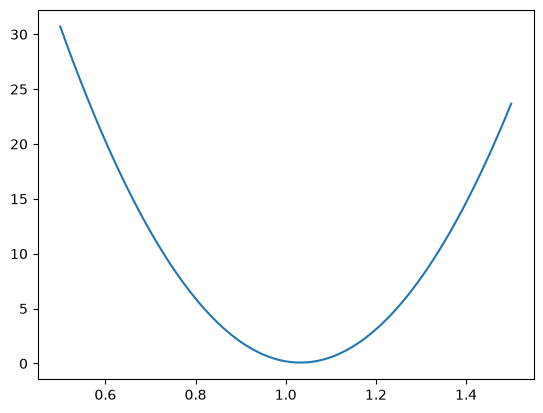

np.float64(1.03)

In [ ]:
b = 1.089
ms = np.linspace(0.5, 1.5, 101)
mse_loss_list = []

# TODO
for m in ms:
    prices_hat = predict(sizes, m, b)
    mse_loss = mse(prices, prices_hat)
    mse_loss_list.append(mse_loss)

mse_losses = np.array(mse_loss_list)

plt.plot(ms, mse_losses)
plt.show()

ms[np.argmin(mse_losses)]


# Shape of the curve: U shaped
# My m = 1.029 is: Near the bottom, slightly left
# Standing at m = 0.7, I'd walk: Down the curve to reduce the loss, or, I would increase m to reduce the loss.

## Bonus — Draw the squares

The squared error of each pizza is literally the **area of a square** drawn on its miss.

**TODO:** Plot the pizza dots and your line. For each pizza, draw a square whose side = the miss.
Use a bad line (e.g. `m = 0.6, b = 4`) so the squares are big enough to see.

*Hints:*
```python
from matplotlib.patches import Rectangle
ax = plt.gca()
ax.add_patch(Rectangle((corner_x, corner_y), width, height, alpha=0.3))
ax.set_aspect("equal")   # so squares look square
```
- The square sits **on the gap** between the dot and the line: corner at `(x, min(y, y_hat))`, side `abs(y - y_hat)`.

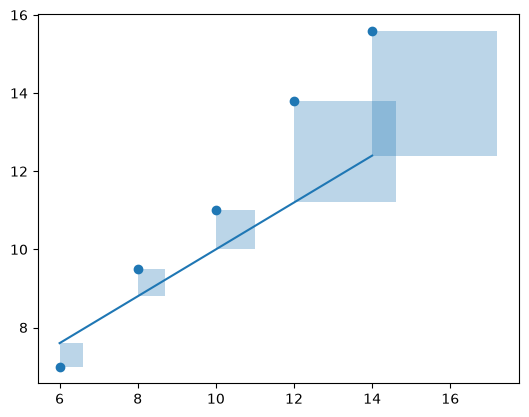

In [38]:
# TODO
from matplotlib.patches import Rectangle
plt.scatter(sizes, prices)
prices_hat = predict(sizes, 0.6, 4)
plt.plot(sizes, prices_hat)
mse_loss = mse(prices, prices_hat)

ax = plt.gca()
for x_i, y_i, y_hat_i in zip(sizes, prices, prices_hat):
    side = abs(y_i - y_hat_i)
    ax.add_patch(
        Rectangle((x_i, min(y_i, y_hat_i)), side, side, alpha=0.3)
    )
ax.set_aspect("equal")   # so squares look square
plt.show()